# IT9002 Lab 3.2: Error Analysis and Classifier Tuning

**Unit 03: Text Classification and Evaluation**

**IT9002 Natural Language Processing**

## Objectives

By the end of this lab, you should be able to:

- Identify the weakest-performing label using per-label evaluation scores and analyze its errors to determine what should be improved.
- Evaluate changes one at a time on the validation set so that the effect of each change can be measured clearly.
- Assess the effect of each change across all labels, since improving one label may reduce performance on another.
- Use the test set only after the final configuration has been selected using the validation set.

## Data

- **Financial PhraseBank v1.0** (Malo, Sinha, Korhonen, Wallenius and Takala, 2014), the 4,217 sentences with more than 66% annotator agreement, Hugging Face `takala/financial_phrasebank`, https://huggingface.co/datasets/takala/financial_phrasebank, CC BY-NC-SA 3.0.

- The course file `financial_phrasebank.csv` (572 KB, on Moodle).

- The course file `fpb_split.csv` (51 KB, on Moodle), which assigns each sentence to the training, validation or test set.

The two files can be downloaded from Moodle. Download them to your computer, then run the cell below. If the files are already available in the runtime, the cell loads them directly; otherwise, it opens a file-upload dialog.

In [1]:
from pathlib import Path
import pandas as pd

def find(name):
    path = next((p for p in (Path(name), Path("data") / name) if p.exists()), None)
    if path is None:
        from google.colab import files
        files.upload()
        path = Path(name)
    return path

df = pd.read_csv(find("financial_phrasebank.csv"))
split = pd.read_csv(find("fpb_split.csv"))["split"]
print(df.shape, split.value_counts().to_dict())

(4217, 2) {'train': 2951, 'validation': 633, 'test': 633}


The file holds 4,217 sentences: 2,951 in the training set and 633 each in the validation and test sets.

## Setup

scikit-learn, NLTK and pandas are preinstalled in Google Colab, so the cell below does not install them there. In other environments, scikit-learn and NLTK will be installed if they are not already available.

In [2]:
import importlib.util, subprocess, sys

for package, module in (("scikit-learn", "sklearn"), ("nltk", "nltk")):
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

The cell below imports the tools used in this lab and prints the versions of pandas, NumPy, NLTK and scikit-learn.

In [3]:
import re
import numpy as np
import matplotlib.pyplot as plt
import nltk
import sklearn
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, f1_score, precision_recall_fscore_support,
                             precision_recall_curve, roc_curve, roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

print("pandas", pd.__version__, "| NumPy", np.__version__, "| NLTK", nltk.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.2 | NumPy 2.4.2 | NLTK 3.9.4 | scikit-learn 1.9.1


## 1. Establishing the Starting Model

The starting point is logistic regression on TF-IDF features with the default settings, trained on the training set and evaluated on the validation set.

The cell below:

- Separates the three sets with the saved split.

- Fits the vectorizer and the model on the training set.

- Prints the classification report on the validation set.

In [4]:
LABELS = ["negative", "neutral", "positive"]
train, val, test = (df[split == name] for name in ("train", "validation", "test"))

tv = TfidfVectorizer()
lr = LogisticRegression(max_iter=1000)
lr.fit(tv.fit_transform(train["sentence"]), train["label"])
val_pred = lr.predict(tv.transform(val["sentence"]))
print(classification_report(val["label"], val_pred, labels=LABELS, digits=3))

              precision    recall  f1-score   support

    negative      0.900     0.351     0.505        77
     neutral      0.761     0.961     0.849       381
    positive      0.770     0.537     0.633       175

    accuracy                          0.769       633
   macro avg      0.810     0.616     0.662       633
weighted avg      0.780     0.769     0.748       633



The **weakest label** is negative, with an F1 of **0.505**. The model is right 9 times out of 10 when it predicts negative (precision 0.900). However, it finds only 27 of the 77 negative sentences (recall 0.351). The macro F1 is 0.662.

The cell below plots the precision, recall and F1 of each label as grouped bars.

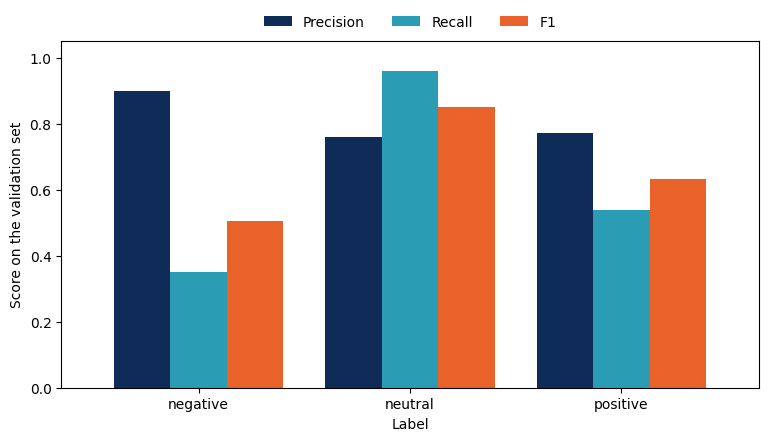

In [5]:
NAVY, TEAL, ORANGE = "#0F2B58", "#2A9DB5", "#E8622A"
precision, recall, f1, _ = precision_recall_fscore_support(val["label"], val_pred, labels=LABELS)
scores = pd.DataFrame({"Precision": precision, "Recall": recall, "F1": f1}, index=LABELS)
ax = scores.plot.bar(figsize=(9, 4.5), width=0.8, color=[NAVY, TEAL, ORANGE], rot=0)
ax.set_xlabel("Label")
ax.set_ylabel("Score on the validation set")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.show()

Negative is the only label whose recall is far below its precision, 0.351 against 0.900. The model rarely predicts negative, and most negative sentences end up predicted as neutral.

## 2. Error Analysis

**Error analysis** examines a classifier's mistakes in a systematic way, so that the next experiment targets the most frequent type of error. It is carried out on the validation set, so that the test set stays unseen:

- **First:** read the confusion matrix to find where the mistakes are.

- **Second:** collect the **most confident mistakes**, which are the wrong predictions made with the highest probability.

- **Third:** group them into categories by what the sentences have in common.

- **Fourth:** choose the next experiment from the largest category.

The cell below prints the confusion matrix, with the actual labels as rows and the predictions as columns.

In [6]:
pd.DataFrame(confusion_matrix(val["label"], val_pred, labels=LABELS),
             index=[f"actual {l}" for l in LABELS], columns=[f"predicted {l}" for l in LABELS])

,predicted negative,predicted neutral,predicted positive
actual negative,27,37,13
actual neutral,0,366,15
actual positive,3,78,94


Of the 50 negative sentences the model misses, **37** are predicted neutral. The largest cell off the diagonal is the 78 positive sentences predicted neutral.

The cell below prints the 10 mistakes made with the highest probability, each with its actual label, its predicted label and that probability.

In [7]:
probabilities = lr.predict_proba(tv.transform(val["sentence"]))
mistakes = val.assign(predicted=val_pred, confidence=probabilities.max(axis=1))
mistakes = mistakes[mistakes["label"] != mistakes["predicted"]]
print(len(mistakes), "mistakes")
for row, r in mistakes.sort_values("confidence", ascending=False).head(10).iterrows():
    print(f"{row:>5} {r['label']:>8} -> {r['predicted']:<8} {r['confidence']:.2f}  {r['sentence']}")

146 mistakes
 1246 positive -> neutral  0.92  `` The CHF is a great product .
 1788 positive -> neutral  0.92  It will combine and renew the contents and functionality of the current systems for funding and online service as well as their maintenance .
 1459 positive -> neutral  0.91  The core of Solidium 's investment strategy is proper , value enhancing asset management of the current holdings .
 1019 negative -> neutral  0.91  As a result of the negotiations the employment of 130 blue - and white-collar employees at the Oulu plant would be terminated .
 3408 negative -> neutral  0.91  The total headcount reduction will be 50 persons , the company said .
 3052 negative -> neutral  0.91  As a result some 20 persons will no longer be needed .
 2763 negative -> neutral  0.89  The contracts of the employees , 96 of whom are blue-collar workers , will be ended between March and August 2011 .
 3655 negative -> neutral  0.87  It is a disappointment to see the plan folded .
 1819 positive ->

The model makes **146** mistakes on the 633 validation sentences, and all 10 of the most confident ones are predictions of **neutral**.

Complete the table below by grouping the 10 sentences into **2 to 4 categories**, named by what the sentences have in common. For each category, give one sentence as an instance and the experiment it suggests.

| Category | Mistakes | Instance | Experiment it suggests |
|---|---|---|---|
| &nbsp; | &nbsp; | &nbsp; | &nbsp; |
| &nbsp; | &nbsp; | &nbsp; | &nbsp; |
| &nbsp; | &nbsp; | &nbsp; | &nbsp; |
| &nbsp; | &nbsp; | &nbsp; | &nbsp; |

## 3. Improving Performance on the Negative Label

**Task:** The classifier should find more of the negative sentences without losing the other two labels. Each change is applied to the starting point alone, so that its effect can be attributed to it.

**Corpus:** The 2,951 training sentences train every candidate, and the 633 validation sentences evaluate it.

Change one decision at a time and evaluate its effect on the validation set. The candidates are:

- **Bigrams:** `ngram_range=(1, 2)` adds a column for every pair of consecutive words.

- **Class weights:** `class_weight="balanced"` makes a mistake on a rare label cost more during training.

- **Stop-word removal:** `stop_words="english"` removes the words of scikit-learn's English stop list.

- **Stemming:** the Porter stemmer reduces every token to its stem, so that `decreased` and `decrease` are counted in the same column.

The selected configuration should satisfy two requirements:

- The F1 of the negative label on the validation set should be **at least 0.54**.

- The F1 of neutral and of positive should not fall by more than **0.01** compared with the starting point.

Then provide evidence for the selected configuration:

- The F1 of each label and the macro F1 for every candidate and for the selected configuration.

- The number of columns of each candidate's matrix.

- The completed decision table.

The cell below defines two functions:

- `stem_tokens()` splits a sentence into the tokens the default vectorizer keeps, words of two or more characters in lowercase, and returns the Porter stem of each.

- `evaluate()` fits the given vectorizer and a logistic regression with the given class weights on the training set. It returns the number of columns, the F1 of each label and the macro F1 on the validation set.

In [8]:
stemmer = PorterStemmer()
token_pattern = re.compile(r"(?u)\b\w\w+\b")

def stem_tokens(sentence):
    return [stemmer.stem(token) for token in token_pattern.findall(sentence.lower())]

def evaluate(vectorizer, class_weight=None):
    model = LogisticRegression(max_iter=1000, class_weight=class_weight)
    model.fit(vectorizer.fit_transform(train["sentence"]), train["label"])
    pred = model.predict(vectorizer.transform(val["sentence"]))
    scores = f1_score(val["label"], pred, labels=LABELS, average=None)
    return {"columns": len(vectorizer.vocabulary_), **{label: round(float(s), 3) for label, s in zip(LABELS, scores)},
            "macro F1": round(float(scores.mean()), 3)}

print(stem_tokens("Net sales decreased by 5 %, and profit decreases."))
print(evaluate(TfidfVectorizer()))

['net', 'sale', 'decreas', 'by', 'and', 'profit', 'decreas']
{'columns': 7596, 'negative': 0.505, 'neutral': 0.849, 'positive': 0.633, 'macro F1': 0.662}


`stem_tokens()` reduces `decreased` and `decreases` to the same stem, `decreas`. The starting point gives a negative F1 of **0.505**, with neutral at 0.849 and positive at 0.633.

In [9]:
# TODO: Evaluate each candidate change on its own, then combinations of the changes that help, and print one row per configuration.


**Expected results:**

- **Bigrams:** negative F1 falls to about **0.396**, with 39,433 columns in place of 7,596.

- **Class weights:** negative F1 rises to about **0.518**, as recall rises and precision falls.

- **Stop-word removal:** negative F1 falls to about **0.444**, because the stop list contains `up` and `down`, which carry the largest coefficients of the positive and negative labels.

- **Stemming:** negative F1 rises to about **0.514**, with 5,959 columns.

- No single change reaches 0.54. **Stemming and class weights** together give about **0.553** for negative, 0.851 for neutral and 0.667 for positive, which meets both requirements.

Complete the table below with **one row** for each candidate change.

In the **Reason** column, support each decision with evidence from the F1 values.

| Change | Negative F1 | Neutral F1 | Positive F1 | Decision | Reason |
|---|---|---|---|---|---|
| Starting point | 0.505 | 0.849 | 0.633 | | |
| Bigrams | | | | | |
| Class weights | | | | | |
| Stop-word removal | | | | | |
| Stemming | | | | | |
| Selected configuration | | | | | |

### Comparing Configurations Across Decision Thresholds

A classifier labels a sentence from its probabilities. A **decision threshold** is the probability of negative above which a sentence is labeled negative, and lowering it identifies more negative sentences at the cost of more false positives. The cell below compares the starting point and the selected configuration on the negative label at every threshold:

- The **precision-recall curve** plots precision against recall as the threshold falls, and **average precision** (AP) summarizes it in one value.

- The **ROC curve** plots the true positive rate, which is the recall, against the false positive rate. The **area under the curve** (AUC) is the probability that a negative sentence receives a higher probability of negative than a sentence of another label.

- The dashed line shows a random ranking.

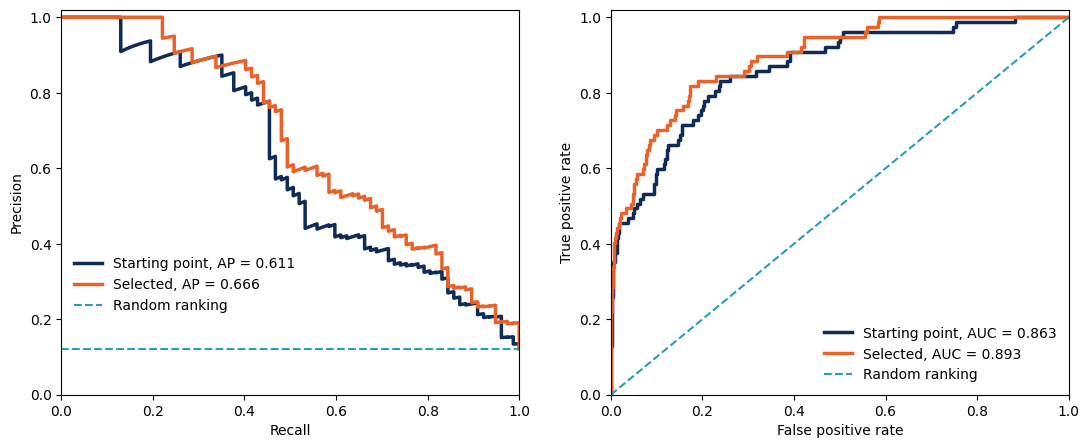

In [10]:
selected_tv = TfidfVectorizer(analyzer=stem_tokens)
selected_lr = LogisticRegression(max_iter=1000, class_weight="balanced")
selected_lr.fit(selected_tv.fit_transform(train["sentence"]), train["label"])

is_negative = (val["label"] == "negative").values
k = list(lr.classes_).index("negative")
p_start = lr.predict_proba(tv.transform(val["sentence"]))[:, k]
p_selected = selected_lr.predict_proba(selected_tv.transform(val["sentence"]))[:, k]

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))
for name, p, color in (("Starting point", p_start, NAVY), ("Selected", p_selected, ORANGE)):
    precision, recall, _ = precision_recall_curve(is_negative, p)
    left.plot(recall, precision, color=color, lw=2.5, label=f"{name}, AP = {average_precision_score(is_negative, p):.3f}")
    fpr, tpr, _ = roc_curve(is_negative, p)
    right.plot(fpr, tpr, color=color, lw=2.5, label=f"{name}, AUC = {roc_auc_score(is_negative, p):.3f}")
left.axhline(is_negative.mean(), color=TEAL, ls="--", label="Random ranking")
right.plot([0, 1], [0, 1], color=TEAL, ls="--", label="Random ranking")
left.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
right.set(xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.02))
left.legend(loc="lower left", bbox_to_anchor=(0.0, 0.18), frameon=False)
right.legend(loc="lower right", frameon=False)
plt.show()

The selected configuration lies above the starting point along most of both curves. Its average precision is **0.666** against 0.611, and its AUC **0.893** against 0.863, so the improvement does not depend on one particular threshold.

The cell below calculates the precision, recall and F1 of the negative label for the selected configuration at thresholds from 0.05 to 0.95, plots the three against the threshold, and prints the threshold with the highest F1.

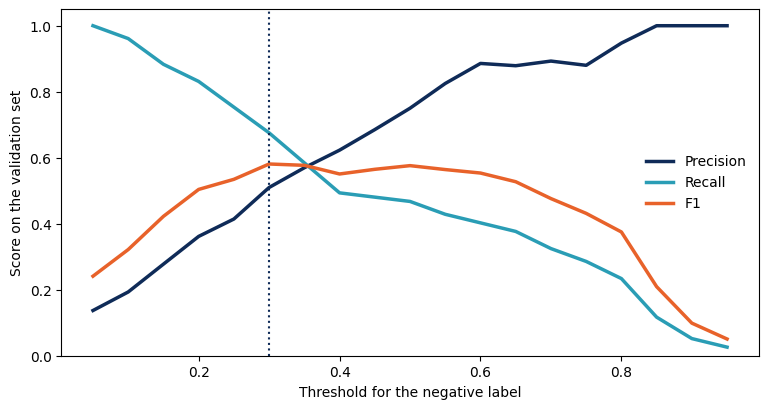

{'threshold': 0.3, 'Precision': 0.51, 'Recall': 0.675, 'F1': 0.581}


In [11]:
rows = []
for threshold in np.arange(0.05, 0.96, 0.05):
    flagged = p_selected >= threshold
    tp = (flagged & is_negative).sum()
    precision = tp / flagged.sum() if flagged.sum() else 1.0
    recall = tp / is_negative.sum()
    f1 = 2 * precision * recall / (precision + recall) if tp else 0.0
    rows.append((round(threshold, 2), precision, recall, f1))
curve = pd.DataFrame(rows, columns=["threshold", "Precision", "Recall", "F1"])

ax = curve.plot(x="threshold", y=["Precision", "Recall", "F1"], figsize=(9, 4.5), lw=2.5, color=[NAVY, TEAL, ORANGE])
best = curve.loc[curve["F1"].idxmax()]
ax.axvline(best["threshold"], color=NAVY, ls=":")
ax.set_xlabel("Threshold for the negative label")
ax.set_ylabel("Score on the validation set")
ax.set_ylim(0, 1.05)
ax.legend(loc="center right", frameon=False)
plt.show()
print(best.round(3).to_dict())

Precision rises and recall falls as the threshold grows. F1 is highest at a threshold of **0.3**, with precision 0.510, recall 0.675 and an F1 of **0.581**, above the 0.553 of the default prediction, which picks the label with the highest probability. A threshold is a setting like any other, so it is chosen on the validation set and then used unchanged on the test set.

## 4. Final Evaluation on the Test Set

The selected configuration is evaluated **once** on the test set, after every choice has been made on the validation set. The starting point is evaluated beside it, so that the change can be read on unseen sentences.

The cell below fits both configurations on the training set, prints the F1 of each label and the macro F1 of both on the test set, and plots their two confusion matrices side by side.

Starting point: macro F1 0.667
    negative 0.522, neutral 0.845, positive 0.633
Selected: macro F1 0.761
    negative 0.697, neutral 0.854, positive 0.731


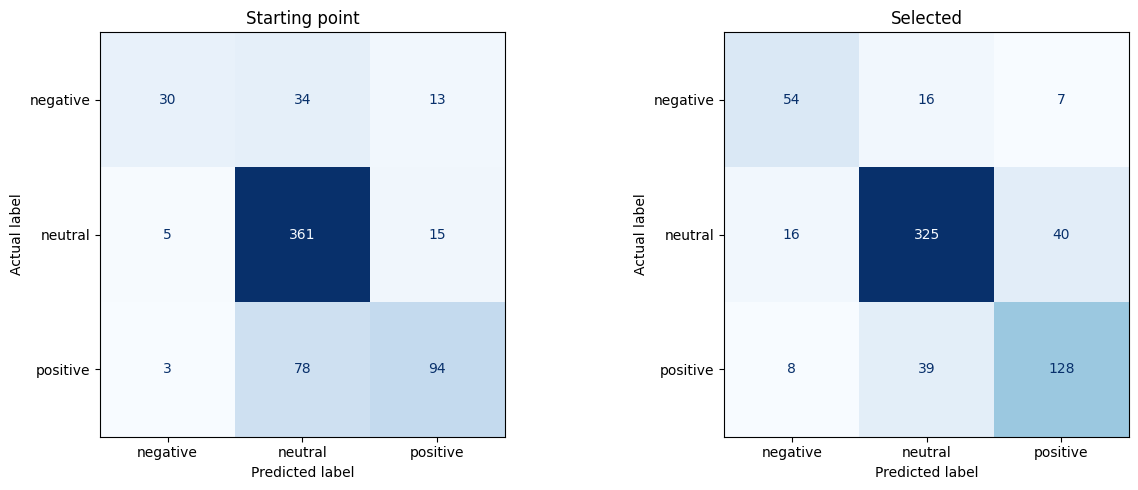

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, vectorizer, weights) in zip(axes, (("Starting point", TfidfVectorizer(), None),
                                                  ("Selected", TfidfVectorizer(analyzer=stem_tokens), "balanced"))):
    model = LogisticRegression(max_iter=1000, class_weight=weights)
    model.fit(vectorizer.fit_transform(train["sentence"]), train["label"])
    test_pred = model.predict(vectorizer.transform(test["sentence"]))
    scores = f1_score(test["label"], test_pred, labels=LABELS, average=None)
    print(f"{name}: macro F1 {scores.mean():.3f}")
    print("   ", ", ".join(f"{label} {s:.3f}" for label, s in zip(LABELS, scores)))
    ConfusionMatrixDisplay.from_predictions(test["label"], test_pred, labels=LABELS, cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=name, xlabel="Predicted label", ylabel="Actual label")
plt.tight_layout()
plt.show()

On the test set the starting point gives a negative F1 of **0.522** and a macro F1 of 0.667, and stemming with class weights gives **0.697** and **0.761**. The matrices show where the gain comes from: the selected configuration identifies **54** of the 77 negative sentences against 30, while labeling 16 neutral sentences as negative against 5. The gain on the test set is larger than on the validation set, which shows how much a result on 633 sentences depends on the particular sentences drawn.

## Exercises

### Exercise 1: Variation Across Cross-Validation Folds

Run **5-fold cross-validation** on the training set for the starting point and for the selected configuration, with `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` and macro F1 as the score. Put the vectorizer and the model in one pipeline, so that each fold learns its own vocabulary. Print the 5 scores, their mean and their standard deviation.

In [13]:
# TODO: Cross-validate both configurations on the training set and print the fold scores, the mean and the standard deviation.


**Expected result:** The starting point gives a mean macro F1 of about **0.668** with a standard deviation of 0.018, and the selected configuration about **0.752** with 0.012. The difference between the means is several times the spread, so the improvement does not depend on one particular split.

### Exercise 2: Evaluating Oversampling for Rare Labels

**Oversampling** repeats training sentences of the rare labels until every label has as many as the most frequent one. Oversample the training set with `np.random.RandomState(42)`, train logistic regression on the default TF-IDF features of the oversampled set, and print the number of negative sentences found on the validation set and the macro F1.

In [14]:
# TODO: Oversample the negative and positive training sentences to 1,773 each, train the model, and print the negatives found and the macro F1 on the validation set.


**Expected result:** The oversampled training set has **5,319** rows. The model finds about **38** of the 77 negative sentences, against 27 without oversampling and 36 with class weights, and its macro F1 is about **0.676**. Copies of a sentence add no new words, so oversampling and class weights have a similar effect.

### Exercise 3 (Extension): Hyperparameter Tuning with Grid Search

A **hyperparameter** is a setting chosen before training. Train logistic regression with balanced class weights for every combination of `C` in 0.1, 1 and 10 and `ngram_range` in (1, 1) and (1, 2). Print the macro F1 of each on the validation set, and plot it against `C` with one line per n-gram range.

In [15]:
# TODO: Print the validation macro F1 for every combination of C and ngram_range, with balanced class weights, and plot it against C.


**Expected result:** The best combination is `ngram_range=(1, 2)` with `C=10`, at about **0.691**. With `C=0.1` both n-gram ranges stay near 0.61, because a small `C` keeps every coefficient small. Bigrams help only once `C` is large enough for their many columns to receive weight, which the plot shows as the two lines crossing between `C=1` and `C=10`.

### Exercise 4 (Extension): Explaining a Misclassification with LIME

**LIME** explains a single prediction by removing words at random and measuring how the predicted probability changes. Install the `lime` package, explain the starting point's prediction for validation sentence `3408` with `LimeTextExplainer(class_names=LABELS, random_state=42)` and 2,000 samples, and print the 6 words with the largest effect on the probability of neutral.

In [16]:
# TODO: Install lime, explain the prediction for sentence 3408, and print the 6 words with the largest effect on neutral.


**Expected result:** The sentence `The total headcount reduction will be 50 persons , the company said .` is negative and is predicted neutral with a probability of about **0.91**. The words `be` and `will` push it toward neutral, while `reduction` and `said` push it away. The model has learned that `will be` is typical of neutral sentences.